# M8230: Diskrétní modely růstu populace – řešení

V tomto notebooku porovnáme čtyři jednoduché diskrétní modely růstu populace:

$$
x(t+1)=r x(t),
$$

$$
x(t+1)=x(t)\left(r-\frac{r-1}{K}x(t)\right),
$$

$$
x(t+1)=\frac{rKx(t)}{K+(r-1)x(t)},
$$

$$
x(t+1)=x(t)\exp\!\left(\left(1-\frac{x(t)}{K}\right)\ln r\right).
$$

Označení:

- $x(t)$ je velikost populace v čase $t$,
- $r$ je růstový parametr,
- $K$ je kapacita prostředí.

Pro všechny modely použijeme stejné počáteční podmínky a stejné hodnoty parametrů. Budeme sledovat, jak se jednotlivé modely liší a jak se jejich chování mění při změně parametrů.

Cílem zatím není všechny pozorované jevy matematicky vysvětlit, ale pomocí numerických experimentů objevit otázky, ke kterým se během semestru vrátíme.

## 1. Definice modelů

Budeme používat zápis

$$
x(t+1)=F(x(t)),
$$

kde funkce $F$ určuje velikost populace v následujícím časovém kroku.

U modelů s regulovaným růstem můžeme psát také

$$
x(t+1)=x(t)g(x(t)),
$$

kde $g(x)$ udává, kolikrát se populace během jednoho časového kroku zvětší nebo zmenší.

Pro jednotlivé modely platí:

$$
g_{\mathrm{M}}(x)=r,
$$

$$
g_{\mathrm{L}}(x)=r-\frac{r-1}{K}x,
$$

$$
g_{\mathrm{BH}}(x)=\frac{rK}{K+(r-1)x},
$$

$$
g_{\mathrm{R}}(x)=\exp\!\left(\left(1-\frac{x}{K}\right)\ln r\right)
= r^{1-x/K}.
$$



### Implementace modelů

V následující buňce:

- načteme knihovny pro výpočty a vykreslování,
- definujeme funkce $F(x)$ určující další stav populace,
- definujeme odpovídající růstové faktory $g(x)$,
- uložíme modely do společného seznamu,
- vytvoříme funkci `simulate`, která postupně vypočítá hodnoty
  $x(0),x(1),\ldots,x(T)$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# Přechodové funkce F(x)

def F_malthus(x, r, K):
    return r*x

def F_logistic(x, r, K):
    return x*(r - (r-1)*x/K)

def F_beverton_holt(x, r, K):
    return (r*K*x)/(K + (r-1)*x)

def F_ricker(x, r, K):
    return x*np.exp((1 - x/K)*np.log(r))

# Růstové faktory g(x)

def g_malthus(x, r, K):
    return r + 0*x

def g_logistic(x, r, K):
    return r - (r-1)*x/K

def g_beverton_holt(x, r, K):
    return (r*K)/(K + (r-1)*x)

def g_ricker(x, r, K):
    return np.exp((1 - x/K)*np.log(r))

models = {
    "Malthus": (F_malthus, g_malthus),
    "Logistic": (F_logistic, g_logistic),
    "Beverton--Holt": (F_beverton_holt, g_beverton_holt),
    "Ricker": (F_ricker, g_ricker),
}

# Výpočet prvních T kroků modelu

def simulate(F, x0, r, K, T):
    x = np.zeros(T+1)
    x[0] = x0
    for t in range(T):
        x[t+1] = F(x[t], r, K)
    return x

ModuleNotFoundError: No module named 'numpy'

## 2. Porovnání časových řad

Pro všechny modely zvolíme stejnou počáteční hodnotu $x(0)$ a stejné parametry $r$ a $K$. Díky tomu můžeme přímo porovnat jejich chování.

Budeme sledovat zejména:

- zda populace roste, klesá nebo se ustálí,
- zda se ke kapacitě prostředí přibližuje plynule, nebo osciluje,
- zda model vytváří biologicky smysluplné hodnoty.

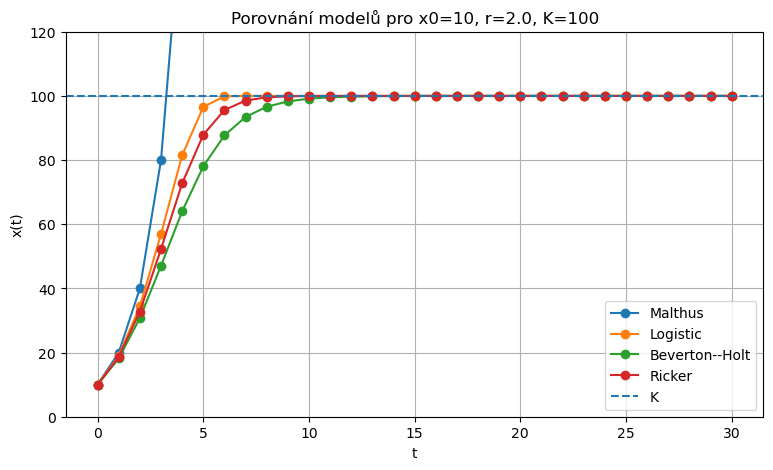

In [ ]:
x0 = 10
r = 2.0
K = 100
T = 30

t = np.arange(T+1)
results = {}

for name, (F, g) in models.items():
    results[name] = simulate(F, x0, r, K, T)

plt.figure(figsize=(9, 5))
for name, x in results.items():
    plt.plot(t, x, marker="o", label=name)

plt.axhline(K, linestyle="--", label="K")
plt.ylim(0, 1.2*K)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(f"Porovnání modelů pro x0={x0}, r={r}, K={K}")
plt.legend()
plt.grid(True)
plt.show()

### Otázky k prvnímu grafu

1. **Který model popisuje neomezený růst?**  
   **Řešení:** Malthusův model. Populace roste geometricky bez omezení.

2. **Které modely se přibližují ke kapacitě prostředí $K$?**  
   **Řešení:** Pro zvolené hodnoty $x(0)=10$, $r=2$ a $K=100$ se ke kapacitě prostředí přibližují logistický, Bevertonův–Holtův a Rickerův model.

3. **Přibližují se všechny modely k hodnotě $K$ stejným způsobem?**  
   **Řešení:** Ne. Bevertonův–Holtův model se ke $K$ přibližuje plynule a relativně pomalu. Logistický model se při těchto parametrech přibližuje rychleji. Rickerův model je také regulovaný. Kvalitativně se všechny tři přibližují stejně.

4. **Co očekáváte, že se změní, pokud zvýšíme parametr $r$?**  
   **Řešení:** U Malthusova modelu očekáváme rychlejší neomezený růst. U regulovaných modelů se může změnit nejen rychlost růstu, ale také kvalitativní chování (mohou se objevit přestřelování hodnoty $K$, oscilace a při dalších změnách parametru i složitější dynamika).

## 3. Regulační funkce $g(x)$

Regulační funkce $g(x)$ určuje růstový faktor populace v jednom časovém kroku:

$$
x(t+1)=x(t)g(x(t)).
$$

Platí:

- pokud $g(x)>1$, populace roste,
- pokud $g(x)<1$, populace klesá,
- pokud $g(x)=1$, velikost populace se nemění.

U logistického modelu je funkce $g(x)$ lineární a pro dostatečně velké hodnoty $x$ může být záporná. U Bevertonova–Holtova a Rickerova modelu zůstává $g(x)$ kladná.

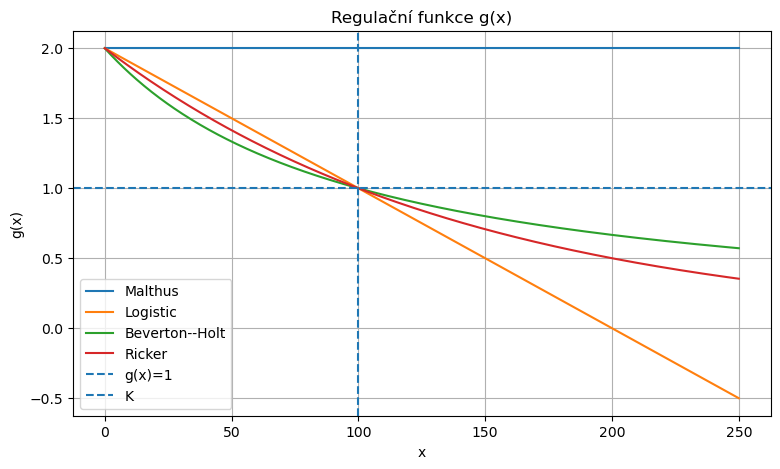

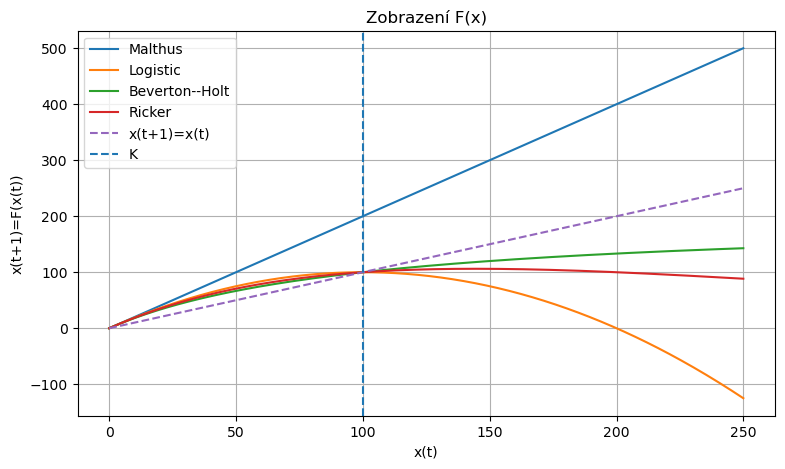

In [ ]:
x_grid = np.linspace(0, 2.5*K, 500)

plt.figure(figsize=(9, 5))
for name, (F, g) in models.items():
    plt.plot(x_grid, g(x_grid, r, K), label=name)
plt.axhline(1, linestyle="--", label="g(x)=1")
plt.axvline(K, linestyle="--", label="K")
plt.xlabel("x")
plt.ylabel("g(x)")
plt.title("Regulační funkce g(x)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))
for name, (F, g) in models.items():
    plt.plot(x_grid, F(x_grid, r, K), label=name)
plt.plot(x_grid, x_grid, linestyle="--", label="x(t+1)=x(t)")
plt.axvline(K, linestyle="--", label="K")
plt.xlabel("x(t)")
plt.ylabel("x(t+1)=F(x(t))")
plt.title("Zobrazení F(x)")
plt.legend()
plt.grid(True)
plt.show()

### Co lze z grafů vyčíst?

Prohlédněte si oba grafy a pokuste se vlastními slovy popsat, co je na nich zajímavé.

1. **Jak se mění růstový faktor jednotlivých modelů, když se populace zvětšuje?**  
   **Řešení:**  
   - **Malthusův model:** $g(x)=r$, takže růstový faktor je konstantní.  
   - **Logistický model:** $g(x)=r-\frac{r-1}{K}x$, takže růstový faktor s rostoucím $x$ lineárně klesá a pro dostatečně velké $x$ může být záporný.  
   - **Bevertonův–Holtův model:** $g(x)=\frac{rK}{K+(r-1)x}$, takže růstový faktor klesá, ale zůstává kladný.  
   - **Rickerův model:** $g(x)=r^{1-x/K}$, takže růstový faktor také klesá a zůstává kladný.

2. **Najdete hodnoty populace, při kterých model předpovídá růst, pokles nebo žádnou změnu?**  
   **Řešení:** U tří regulovaných modelů pro $r>1$ platí:
   - pokud $x<K$, potom $g(x)>1$ a populace roste,
   - pokud $x=K$, potom $g(x)=1$ a populace se nemění,
   - pokud $x>K$, potom $g(x)<1$ a model vytváří tlak na pokles populace.

   U Malthusova modelu s $r=2$ je $g(x)=2>1$ pro každé $x$, takže populace stále roste.

3. **Objevuje se u některého modelu chování, které by mohlo být biologicky problematické?**  
   **Řešení:** Ano. U logistického modelu může být pro dostatečně velké $x$ růstový faktor $g(x)<0$, a tedy i $x(t+1)<0$. Záporná velikost populace biologicky nedává smysl. Bevertonův–Holtův a Rickerův model tuto konkrétní potíž nemají, protože jejich růstový faktor zůstává kladný.

4. **Formulujte jednu otázku, kterou byste chtěli na základě těchto grafů dále zkoumat.**  
   **Možná odpověď:** Jak velký může být parametr $r$, aby byla rovnováha $x=K$ stabilní, a kdy se místo konvergence začnou objevovat trvalé oscilace?

### Shrnutí pozorování

**Model s konstantním růstovým faktorem:** Malthusův model.

**Model, u kterého může být růstový faktor záporný:** logistický model.

**Hodnota populace, při které se regulované modely nemění:** $x=K$.

**Nejzajímavější rozdíl mezi modely:** Stejná kapacita prostředí $K$ ještě neznamená stejnou dynamiku. Modely se liší způsobem regulace a při větších hodnotách $r$ mohou reagovat kvalitativně odlišně.

**Otázka pro další zkoumání:** Kdy je rovnováha $x=K$ stabilní a kdy se objeví periodické nebo složitější chování?

## 4. Bevertonův–Holtův model a explicitní vzorec

Bevertonův–Holtův model

$$
x(t+1)=\frac{rKx(t)}{K+(r-1)x(t)}
$$

má explicitní řešení

$$
x(t)=\frac{Kx(0)r^t}{K+x(0)(r^t-1)}.
$$

Odvození tohoto vzorce budeme řešit později během semestru. Nyní pouze numericky ověříme, že iterace rekurentní formule a explicitní vzorec dávají stejné hodnoty.

### Řešení

Po spuštění následující buňky se hodnoty získané iterací a explicitním vzorcem překrývají. Maximální rozdíl je pouze na úrovni numerického zaokrouhlení. Numerický experiment tedy potvrzuje, že uvedený explicitní vzorec odpovídá Bevertonovu–Holtovu modelu se stejnou počáteční podmínkou.

Maximální absolutní chyba: 2.842170943040401e-14


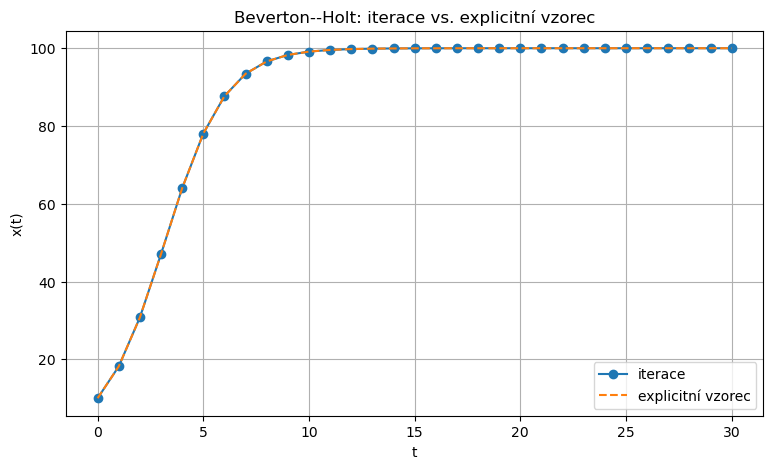

In [ ]:
def beverton_holt_explicit(t, x0, r, K):
    return (K*x0*(r**t))/(K + x0*(r**t - 1))

x_bh_iter = simulate(F_beverton_holt, x0, r, K, T)
x_bh_exp = beverton_holt_explicit(t, x0, r, K)

max_error = np.max(np.abs(x_bh_iter - x_bh_exp))
print("Maximální absolutní chyba:", max_error)

plt.figure(figsize=(9, 5))
plt.plot(t, x_bh_iter, marker="o", label="iterace")
plt.plot(t, x_bh_exp, linestyle="--", label="explicitní vzorec")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Beverton--Holt: iterace vs. explicitní vzorec")
plt.legend()
plt.grid(True)
plt.show()

## 5. Kdy logistický model dává zápornou hodnotu?

Logistický model má tvar

$$
x(t+1)=x(t)\left(r-\frac{r-1}{K}x(t)\right).
$$

Pro $x(t)>0$ bude hodnota v následujícím časovém kroku záporná, pokud

$$
r-\frac{r-1}{K}x(t)<0.
$$

Pro $r>1$ dostáváme podmínku

$$
x(t)>\frac{rK}{r-1}.
$$

Pokud tedy velikost populace překročí tuto mez, logistický model předpoví zápornou hodnotu populace. To ukazuje, že pro příliš velké počáteční hodnoty nemusí být tento model biologicky vhodný. Pro zvolené hodnoty $r$ a $K$ vypočítejte tuto mez a ověřte ji numericky.

### Řešení

Pro $r=2$ a $K=100$ je mez

$$
\frac{rK}{r-1}
=
\frac{2\cdot100}{1}
=
200.
$$

Proto:
- pro $0<x<200$ je další hodnota nezáporná,
- pro $x=200$ dostaneme $x(t+1)=0$,
- pro $x>200$ dostaneme $x(t+1)<0$.

Například pro $x(t)=210$:

$$
x(t+1)
=
210\left(2-\frac{210}{100}\right)
=
-21.
$$

Záporná populace biologicky nedává smysl. Tento výsledek tedy ukazuje omezení diskrétního logistického modelu mimo vhodnou oblast stavového prostoru.

Pro r = 2.0 a K = 100 dává logistický model zápornou hodnotu pro x > 200.0


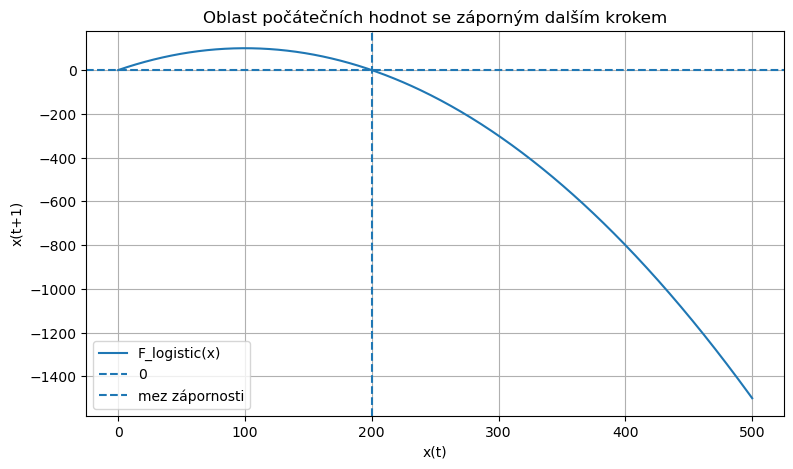

In [ ]:
threshold = r*K/(r-1)
print("Pro r =", r, "a K =", K, "dává logistický model zápornou hodnotu pro x >", threshold)

x_grid2 = np.linspace(0, 2.5*threshold, 500)
F_log = F_logistic(x_grid2, r, K)

plt.figure(figsize=(9, 5))
plt.plot(x_grid2, F_log, label="F_logistic(x)")
plt.axhline(0, linestyle="--", label="0")
plt.axvline(threshold, linestyle="--", label="mez zápornosti")
plt.xlabel("x(t)")
plt.ylabel("x(t+1)")
plt.title("Oblast počátečních hodnot se záporným dalším krokem")
plt.legend()
plt.grid(True)
plt.show()

## 6. Oscilace pro větší hodnoty parametru $r$

Chování modelu se může výrazně změnit při změně parametru $r$.

V následujících grafech budeme sledovat logistický a Rickerův model pro několik různých hodnot parametru $r$.

Zaměřte se na dlouhodobé chování populace:

- **Přibližuje se populace ke kapacitě prostředí $K$?**  
  **Řešení:** Pro menší z testovaných hodnot $r$ ano. U logistického modelu pro $r=2.5$ a u Rickerova modelu pro $r=5$ se řešení postupně přibližuje ke $K=100$.

- **Přibližuje se k ní plynule, nebo hodnotu $K$ opakovaně překračuje?**  
  **Řešení:** U obou modelů se při zvolených vyšších hodnotách $r$ objevuje přestřelování hodnoty $K$ a oscilace.

- **Ustálí se oscilace, nebo pokračují i po dlouhé době?**  
  **Řešení:** Pro logistický model s $r=2.5$ a Rickerův model s $r=5$ jsou oscilace tlumené. Pro logistický model s $r=3.2$ a Rickerův model s $r=8$ už oscilace dlouhodobě přetrvávají.

- **Objeví se při zvýšení parametru $r$ nový typ chování?**  
  **Řešení:** Ano. U logistického modelu se při $r=3.2$ objeví stabilní perioda 2 a při $r=3.5$ přibližně perioda 4. Zvýšení $r$ tedy nemění jen rychlost růstu, ale může změnit samotný typ dlouhodobé dynamiky.

- **Chovají se logistický a Rickerův model při podobných hodnotách $r$ stejně?**  
  **Řešení:** Ne. Oba modely mohou vykazovat tlumené i trvalé oscilace, ale hranice změny chování a konkrétní hodnoty parametrů jsou různé, protože regulační mechanismus je v každém modelu jiný.

### Shrnutí pozorování

**Model, u kterého jsme pozorovali tlumené oscilace:** logistický model pro $r=2.5$ a Rickerův model pro $r=5$.

**Model, u kterého oscilace dlouhodobě přetrvávaly:** logistický model například pro $r=3.2$ a Rickerův model například pro $r=8$.

**Hodnota parametru $r$, při které se chování výrazně změnilo:** v našem numerickém experimentu je změna dobře vidět mezi $r=2.5$ a $r=3.2$ u logistického modelu a mezi $r=5$ a $r=8$ u Rickerova modelu.

**Nejzajímavější pozorovaný jev:** zvýšení růstového parametru nemusí znamenat pouze rychlejší růst; může způsobit přechod od stabilní rovnováhy k periodickým oscilacím.

**Otázka, kterou bychom chtěli později matematicky vysvětlit:** Jak lze z vlastností přechodové funkce $F$, například z derivace v rovnováze, určit ztrátu stability a vznik oscilací?

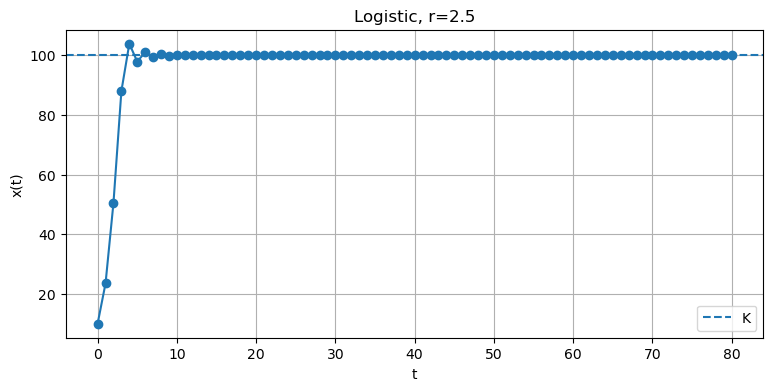

Posledních 50 hodnot: min=100, max=100


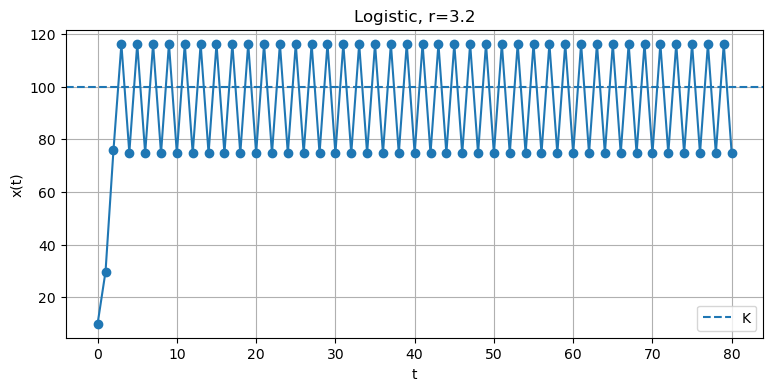

Posledních 50 hodnot: min=74.62, max=116.3


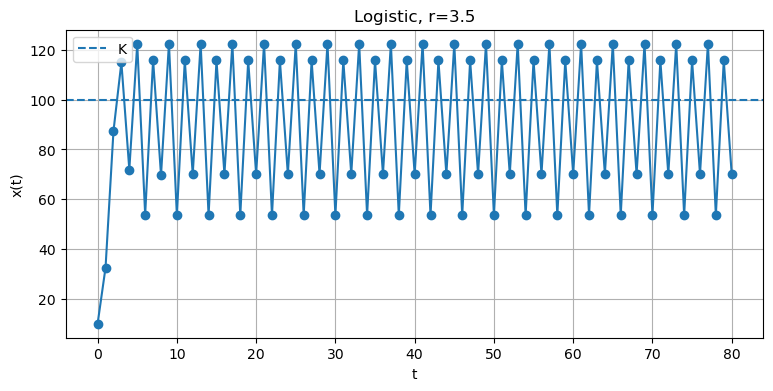

Posledních 50 hodnot: min=53.59, max=122.5


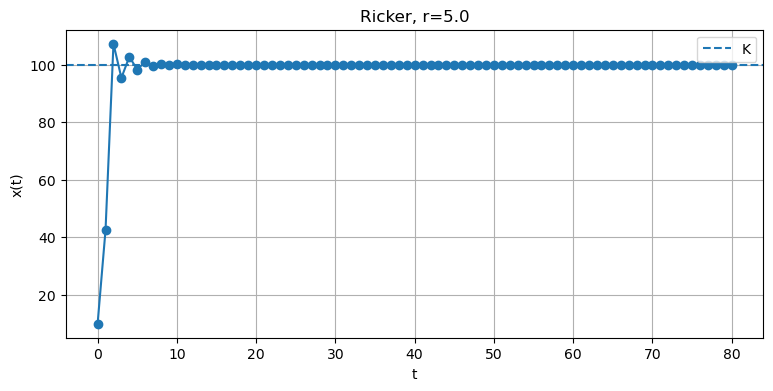

Posledních 50 hodnot: min=100, max=100


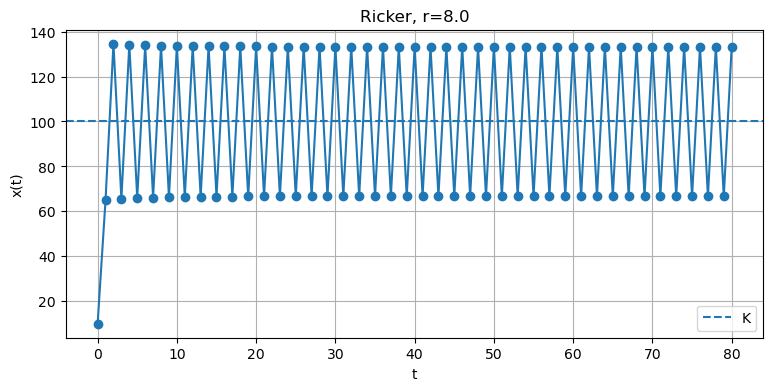

Posledních 50 hodnot: min=66.66, max=133.3


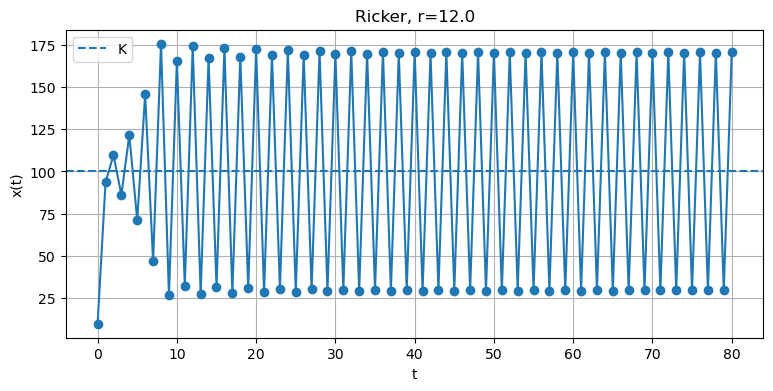

Posledních 50 hodnot: min=29.27, max=171


In [ ]:
def plot_time_series_for_r_values(model_name, F, r_values, x0=10, K=100, T=80, last=50):
    for rv in r_values:
        x = simulate(F, x0, rv, K, T)
        plt.figure(figsize=(9, 4))
        plt.plot(np.arange(T+1), x, marker="o")
        plt.axhline(K, linestyle="--", label="K")
        plt.xlabel("t")
        plt.ylabel("x(t)")
        plt.title(f"{model_name}, r={rv}")
        plt.legend()
        plt.grid(True)
        plt.show()
        print(f"Posledních {last} hodnot: min={np.min(x[-last:]):.4g}, max={np.max(x[-last:]):.4g}")

plot_time_series_for_r_values("Logistic", F_logistic, [2.5, 3.2, 3.5], x0=x0, K=K, T=80)
plot_time_series_for_r_values("Ricker", F_ricker, [5.0, 8.0, 12.0], x0=x0, K=K, T=80)

## 7. Samostatný experiment

Vyberte si jednu z následujících otázek:

1. Jak ovlivňuje parametr $r$ dlouhodobé chování jednotlivých modelů?
2. Jak ovlivňuje počáteční hodnota $x(0)$ další vývoj populace?
3. Které modely zůstávají biologicky smysluplné i pro velmi velkou počáteční populaci?
4. Dokážete najít dvě hodnoty parametrů, při kterých se stejný model chová kvalitativně odlišně?

Při experimentování měňte vždy pouze jeden parametr a ostatní ponechte stejné. Pokud si nejste jisti dlouhodobým chováním, zvětšete počet časových kroků $T$.

### Záznam experimentu – řešení

**Zvolená výzkumná otázka:** Dokážeme najít dvě hodnoty parametru $r$, při kterých se stejný model chová kvalitativně odlišně?

**Model nebo modely, které zkoumáme:** diskrétní logistický model

$$
x(t+1)=x(t)\left(r-\frac{r-1}{K}x(t)\right).
$$

**Neměněné hodnoty parametrů:** $x(0)=10$, $K=100$ a $T=80$.

**Měněný parametr:** $r$.

**Vyzkoušené hodnoty parametru:** $r=2.5$ a $r=3.2$.

**Co jsme před experimentem očekávali:** Vyšší hodnota $r$ by měla způsobit silnější reakci populace na rozdíl mezi aktuální velikostí populace a kapacitou prostředí. Očekáváme proto výraznější přestřelování hodnoty $K$.

**Co jsme pozorovali:** Pro $r=2.5$ řešení kolem $K$ osciluje, ale amplituda postupně klesá a populace konverguje ke $K=100$. Pro $r=3.2$ oscilace nezanikají a dlouhodobě se střídají přibližně dvě hodnoty.

**Našli jsme oscilace nebo jiné zajímavé chování:** Ano. Pro $r=2.5$ jsou oscilace tlumené, zatímco pro $r=3.2$ přetrvávají a vytvářejí periodu 2.

**Objevil se biologicky problematický výsledek:** V tomto konkrétním experimentu ne; hodnoty zůstávají kladné. Logistický model však pro jiné kombinace parametrů a dostatečně velké stavy může vytvořit zápornou hodnotu populace.

**Náš hlavní závěr:** Parametr $r$ neovlivňuje pouze rychlost růstu. Jeho změna může změnit kvalitativní typ dlouhodobé dynamiky modelu.

**Otázka, kterou bychom chtěli dále zkoumat:** Pro jakou přesnou hodnotu $r$ ztrácí rovnováha $x=K$ stabilitu a proč se poté objeví periodické řešení?

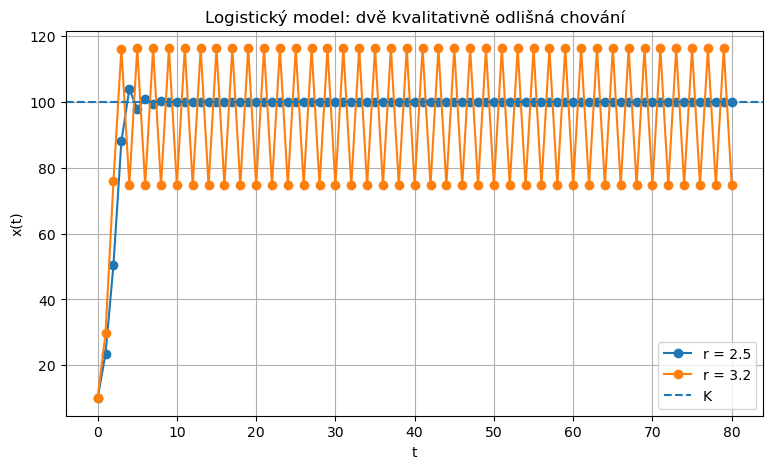

r = 2.5
posledních 10 hodnot: [100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]

r = 3.2
posledních 10 hodnot: [116.2844  74.6247 116.2844  74.6247 116.2844  74.6247 116.2844  74.6247
 116.2844  74.6247]



In [ ]:

# Řešený vlastní experiment:
# logistický model pro dvě hodnoty parametru r.

x0_exp = 10
K_exp = 100
T_exp = 80
r_values_exp = [2.5, 3.2]

plt.figure(figsize=(9, 5))

for r_exp in r_values_exp:
    x = simulate(F_logistic, x0_exp, r_exp, K_exp, T_exp)
    plt.plot(
        np.arange(T_exp + 1),
        x,
        marker="o",
        label=f"r = {r_exp}"
    )

plt.axhline(K_exp, linestyle="--", label="K")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Logistický model: dvě kvalitativně odlišná chování")
plt.legend()
plt.grid(True)
plt.show()

for r_exp in r_values_exp:
    x = simulate(F_logistic, x0_exp, r_exp, K_exp, T_exp)
    print(f"r = {r_exp}")
    print("posledních 10 hodnot:", np.round(x[-10:], 4))
    print()
